# 02 — Eksperimen & Hasil Model

Membaca artefak hasil `make tune` dan `make train` (`outputs/`). Semua angka di README berasal dari file yang sama.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (12, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
import json, yaml
from src.config import load_config
from src.models import MODEL_LABELS
cfg = load_config()
LABEL = {k: v["label"] for k, v in cfg["commodities"].items()}
metrics = pd.read_csv("outputs/metrics.csv")
preds = pd.read_parquet("outputs/backtest_predictions.parquet")
print(json.dumps(json.load(open("outputs/run_info.json")), indent=1)[:600])

{
 "run_at": "2026-09-24T23:55:47",
 "data_start": "2018-01-01",
 "data_end": "2026-09-24",
 "n_series": 10,
 "folds": {
  "horizons": [
   7,
   14,
   30
  ],
  "max_horizon": 30,
  "n_folds": 12,
  "test_size": 30,
  "holdout_days": 90,
  "intervals": [
   0.8,
   0.95
  ]
 },
 "seed": 42,
 "python": "3.12.6",
 "models": {
  "naive": null,
  "seasonal_naive": null,
  "arima": {
   "seasonal": true,
   "m": 7,
   "max_p": 3,
   "max_q": 3,
   "max_P": 1,
   "max_Q": 1,
   "select_train_days": 1095
  },
  "prophet": {
   "changepoint_prior_scale": 0.426359366040766,
   "seasonality_prior_scal


## 1. Hasil tuning (Optuna)

Objektif: MASE H7 pada 4 fold backtest terakhir untuk beras & cabai rawit nasional.

In [3]:
print(open("configs/best_params.yaml").read())
from pathlib import Path
for f in sorted(Path("outputs/tuning").glob("trials_*.csv")):
    t = pd.read_csv(f)
    print(f.stem, "trial:", len(t), "| MASE default (trial 0):", round(t.loc[0, "value"], 4), "| terbaik:", round(t["value"].min(), 4))

# Dihasilkan otomatis oleh `make tune` â€” menimpa parameter default di config.yaml
lstm:
  dropout: 0.38625281322982374
  hidden_size: 32
  lr: 0.0015635108708133452
  num_layers: 2
  window: 60
prophet:
  changepoint_prior_scale: 0.426359366040766
  holidays_prior_scale: 0.03836588186613471
  seasonality_prior_scale: 0.015711298625546165
xgboost:
  colsample_bytree: 0.6777677500493654
  learning_rate: 0.012720570987354327
  max_depth: 2
  min_child_weight: 1.3023993483824934
  n_estimators: 100
  reg_lambda: 9.446391745160764
  subsample: 0.8727984642891312

trials_lstm trial: 12 | MASE default (trial 0): 1.2127 | terbaik: 1.1477
trials_prophet trial: 30 | MASE default (trial 0): 5.5541 | terbaik: 4.9117
trials_xgboost trial: 30 | MASE default (trial 0): 2.2939 | terbaik: 1.0904


## 2. Leaderboard backtest, horizon 7 hari

In [4]:
h7 = metrics[(metrics.split == "backtest") & (metrics.horizon == 7)]
pivot = h7.pivot_table(index=["region", "commodity"], columns="model", values="mase")
pivot.style.highlight_min(axis=1, props="font-weight:bold").format("{:.3f}")

In [5]:
h7.pivot_table(index=["region", "commodity"], columns="model", values="mape").round(2)

model                          arima  lstm  naive  prophet  seasonal_naive  \
region   commodity                                                           
diy      bawang_merah           3.01  3.26   2.56    15.46            3.07   
         bawang_putih           0.13  0.39   0.13     3.70            0.70   
         beras_medium_1         0.01  0.06   0.00     1.88            0.07   
         cabai_merah_keriting   4.81  5.06   4.81    29.94           10.06   
         cabai_rawit_merah      7.50  6.31   5.53    28.30           11.24   
nasional bawang_merah           1.81  1.61   1.70    12.72            3.27   
         bawang_putih           0.29  0.44   0.29     4.03            0.65   
         beras_medium_1         0.22  0.16   0.10     1.31            0.14   
         cabai_merah_keriting   3.74  3.62   3.86    19.55            7.07   
         cabai_rawit_merah      4.58  3.74   4.15    14.22            7.74   

model                          xgboost  
region   commodity                      
diy      bawang_merah             3.07  
         bawang_putih             0.44  
         beras_medium_1           0.02  
         cabai_merah_keriting     5.24  
         cabai_rawit_merah        6.53  
nasional bawang_merah             1.42  
         bawang_putih             0.30  
         beras_medium_1           0.15  
         cabai_merah_keriting     4.08  
         cabai_rawit_merah        4.09

## 3. Pemenang per deret & perbandingan dengan target PRD

In [6]:
best = pd.read_csv("outputs/best_models.csv")
hold = metrics[(metrics.split == "holdout") & (metrics.horizon == 7)][["region", "commodity", "model", "mape", "rel_mase"]]
best = best.merge(hold, on=["region", "commodity", "model"], suffixes=("", "_holdout"))
best["target_mape"] = np.where(best.commodity.str.startswith("beras"), 3, 12)
best["lolos_target_mape"] = best["mape"] < best["target_mape"]
best["kalahkan_naive"] = best["rel_mase"] < 1
best

,region,commodity,model,mase,rel_mase,mape,mape_holdout,rel_mase_holdout,target_mape,lolos_target_mape,kalahkan_naive
0,diy,bawang_merah,arima,5.56,1.16,3.01,4.25,1.02,12,True,False
1,diy,bawang_putih,arima,0.35,1.00,0.13,3.04,1.00,12,True,False
2,diy,beras_medium_1,arima,0.22,NaN,0.01,0.34,1.00,3,True,False
3,diy,cabai_merah_keriting,arima,2.67,1.00,4.81,2.69,1.00,12,True,False
4,diy,cabai_rawit_merah,lstm,3.70,1.19,6.31,4.03,0.70,12,True,False
5,nasional,bawang_merah,xgboost,1.96,0.84,1.42,2.15,0.81,12,True,True
6,nasional,bawang_putih,arima,0.55,1.00,0.29,1.04,0.99,12,True,True
7,nasional,beras_medium_1,xgboost,0.61,1.46,0.15,0.07,2.50,3,True,False
8,nasional,cabai_merah_keriting,lstm,2.75,0.94,3.62,3.58,1.00,12,True,True
9,nasional,cabai_rawit_merah,lstm,2.58,0.88,3.74,2.85,0.74,12,True,True


## 4. Error per horizon (rata-rata semua deret)

In [7]:
agg = metrics[metrics.split == "backtest"].groupby(["model", "horizon"])[["mape", "rel_mase", "coverage80", "coverage95", "directional_acc"]].mean()
agg.unstack("horizon").round(2)

mape             rel_mase           coverage80              \
horizon           7     14    30       7    14   30         7     14    30   
model                                                                        
arima           2.61  4.50  7.27     1.21 1.17 1.10      91.07 88.15 85.58   
lstm            2.47  4.14  6.65     1.37 1.28 1.15      84.40 83.33 82.75   
naive           2.31  4.06  7.10     1.00 1.00 1.00      92.98 90.42 89.53   
prophet        13.11 13.80 14.47     9.60 7.67 4.14      57.62 56.31 56.11   
seasonal_naive  4.40  5.52  7.96     2.22 1.51 1.17      90.71 88.93 88.00   
xgboost         2.53  4.18  6.84     1.36 1.21 1.12      73.45 72.20 70.06   

               coverage95             directional_acc              
horizon                7     14    30              7     14    30  
model                                                              
arima               96.90 95.30 94.61           45.95 45.24 43.47  
lstm                95.83 95.36 94.33           31.79 35.89 42.92  
naive               97.62 96.96 97.50           42.38 34.29 24.72  
prophet             77.86 78.10 77.42           25.24 31.90 40.97  
seasonal_naive      97.02 97.20 97.78           39.29 40.12 39.08  
xgboost             88.93 87.14 84.00           36.43 39.94 43.61

Text(0.0, 1.0, 'MAPE per langkah — rata-rata 10 deret, 12 fold backtest')

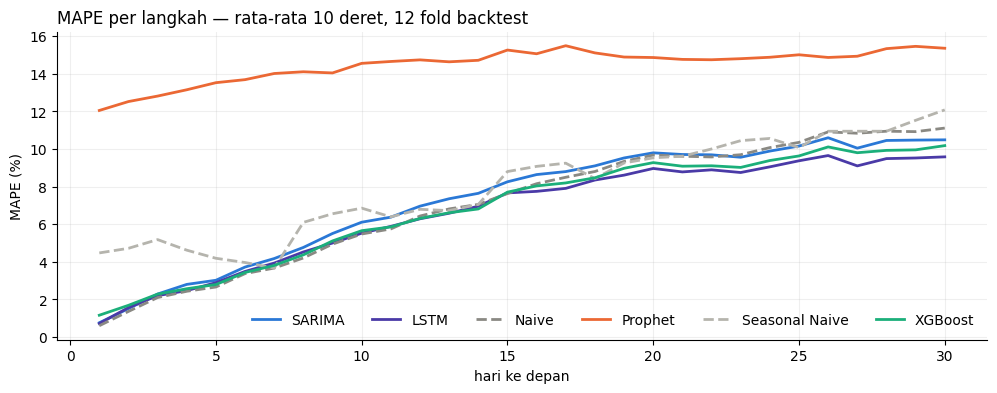

In [8]:
colors = {"arima": "#2a78d6", "prophet": "#eb6834", "xgboost": "#1baf7a", "lstm": "#4a3aa7", "naive": "#8a8983", "seasonal_naive": "#b5b4ad"}
p = preds[preds.split == "backtest"].assign(ape=lambda d: 100 * (d.y_true - d.yhat).abs() / d.y_true)
fig, ax = plt.subplots(figsize=(12, 4))
for m, g in p.groupby("model"):
    s = g.groupby("step")["ape"].mean()
    ax.plot(s.index, s, color=colors.get(m), lw=2, ls="--" if "naive" in m else "-", label=MODEL_LABELS[m])
ax.set_xlabel("hari ke depan"); ax.set_ylabel("MAPE (%)"); ax.legend(frameon=False, ncol=6)
ax.set_title("MAPE per langkah — rata-rata 10 deret, 12 fold backtest", loc="left")

## 5. Error pada periode normal vs lonjakan

PRD risiko: laporkan error per periode normal vs lonjakan. Lonjakan = |perubahan aktual dari origin| > 15% pada tanggal target.

In [9]:
p["lonjakan"] = (p.y_true / p.y_origin - 1).abs() > 0.15
p[p.step <= 7].groupby(["model", "lonjakan"])["ape"].mean().unstack().rename(columns={False: "normal", True: "lonjakan"}).round(2)

lonjakan,normal,lonjakan
model,,
arima,1.97,20.40
lstm,1.92,17.80
naive,1.69,19.87
prophet,12.74,23.53
seasonal_naive,3.70,24.05
xgboost,1.96,18.47


## 6. Uji Diebold-Mariano (pemenang vs runner-up)

In [10]:
pd.read_csv("outputs/dm_test.csv")

,region,commodity,best,runner_up,horizon,dm_stat,p_value,n,significant_5pct
0,diy,bawang_merah,arima,naive,7,1.62,0.11,84,False
1,diy,bawang_putih,arima,naive,7,NaN,NaN,84,False
2,diy,beras_medium_1,arima,naive,7,0.99,0.33,84,False
3,diy,cabai_merah_keriting,arima,naive,7,NaN,NaN,84,False
4,diy,cabai_rawit_merah,lstm,naive,7,0.34,0.74,84,False
5,nasional,bawang_merah,xgboost,lstm,7,-0.76,0.45,84,False
6,nasional,bawang_putih,arima,naive,7,-2.20,0.03,84,True
7,nasional,beras_medium_1,xgboost,naive,7,1.64,0.11,84,False
8,nasional,cabai_merah_keriting,lstm,arima,7,0.42,0.67,84,False
9,nasional,cabai_rawit_merah,lstm,xgboost,7,-1.00,0.32,84,False


## 7. Waktu komputasi

Rata-rata detik per fold (training) — pertimbangan praktis selain akurasi.

In [11]:
metrics.drop_duplicates(["region", "commodity", "model"]).groupby("model")[["train_time_s", "infer_time_s"]].mean().sort_values("train_time_s").round(3)

,train_time_s,infer_time_s
model,,
naive,0.00,0.00
seasonal_naive,0.00,0.00
arima,6.86,0.01
xgboost,7.42,0.63
prophet,24.01,1.07
lstm,63.02,0.03
